# VGG16 from Scratch with Keras
## Image Recognition with a Pretrained ImageNet Model

This notebook is designed for classroom teaching. We will:

1. Understand the important ideas behind VGG16.
2. Build the complete VGG16 architecture from scratch using Keras.
3. Display the architecture as a block diagram.
4. Explain why training VGG16 from scratch is not practical in a short class.
5. Load VGG16 with pretrained ImageNet weights.
6. Use it to recognize objects in a sample image and an uploaded image.

> **Colab tip:** Select **Runtime → Change runtime type → T4 GPU**. The pretrained weights are about 528 MB, so the first download can take a few minutes.

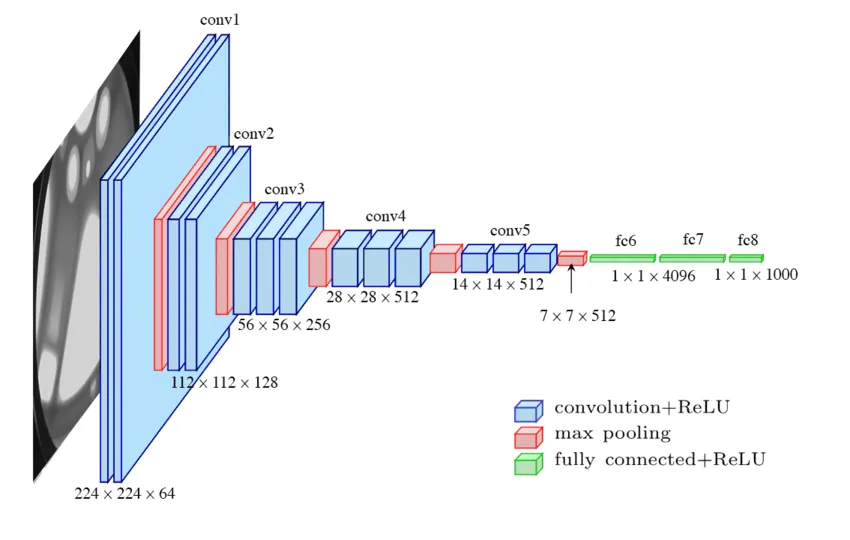

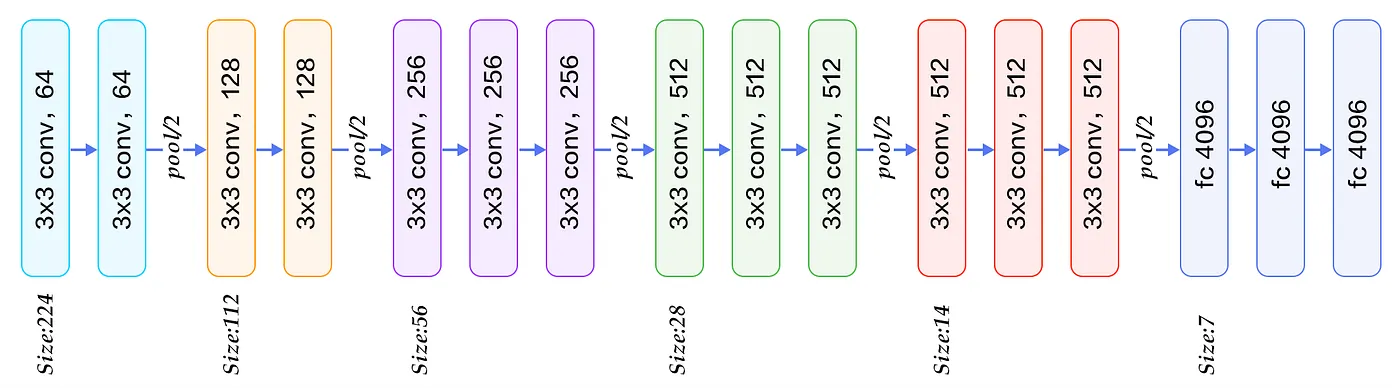

## Essential VGG16 Theory

**Background**

- VGG16 was developed by **Karen Simonyan and Andrew Zisserman** at the Visual Geometry Group, University of Oxford.
- Their work studied how increasing CNN depth improves large-scale image recognition. It was submitted in 2014 and published at ICLR 2015.
- VGG16 performed strongly in the ImageNet Large Scale Visual Recognition Challenge 2014 and became an important feature extractor for later computer-vision systems.
- The number **16** refers to the layers that contain trainable weights: **13 convolution layers + 3 fully connected layers**. Pooling and activation layers are not included in that count.

**Main design ideas**

- Every convolution uses a small **3 × 3 filter**, stride 1, and same padding.
- Multiple 3 × 3 convolutions are stacked. Two stacked 3 × 3 layers see approximately the same region as one 5 × 5 layer, but add another nonlinearity and can use fewer weights.
- Each convolution is followed by a **ReLU** activation, which introduces nonlinearity and helps the network learn complex patterns.
- Each block ends with **2 × 2 max pooling** with stride 2. Pooling halves the width and height.
- Channel depth grows from 64 to 128, 256, and 512, allowing deeper layers to represent richer visual patterns.
- Early layers tend to detect edges and textures; middle layers combine them into shapes and parts; later layers respond to higher-level object features.

**Input and output**

- Standard VGG16 receives a **224 × 224 RGB image**, represented as a tensor of shape `(224, 224, 3)`.
- After five pooling operations, the tensor has shape **7 × 7 × 512**. Flattening it produces 25,088 values.
- Two dense layers contain 4,096 neurons each. The final softmax layer returns probabilities for **1,000 ImageNet classes**.
- The complete network has **138,357,544 trainable parameters**. Most of them are in the first two dense layers.

**Pretraining and transfer learning**

- Training from scratch means starting with random weights and learning from a very large labeled dataset. This requires substantial data, time, and computing power.
- A pretrained model already contains useful visual features learned from ImageNet. We can use it directly for ImageNet recognition.
- For a new task, we can remove the original classifier, freeze the convolution base, and train a small new classifier. This is called **transfer learning**.

**Strengths and limitations**

- **Strengths:** regular architecture, easy to understand, strong reusable features, and widely used for teaching and transfer learning.
- **Limitations:** approximately 138 million parameters, a large model file, slow inference compared with modern efficient CNNs, and no residual connections.
- The ImageNet model can only choose among its 1,000 learned labels; a confident prediction is not proof that the model truly understands the scene.

**Further reading:** [Original VGG paper](https://arxiv.org/abs/1409.1556) · [Official Keras VGG16 documentation](https://keras.io/api/applications/vgg/vgg_models/) · [Official VGG preprocessing documentation](https://keras.io/api/applications/vgg/vgg_preprocessing/)

## 1. Import the libraries

In [1]:
import gc
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Layer-by-layer architecture

| Stage | Layers | Output shape |
|---|---|---:|
| Input | RGB image | 224 × 224 × 3 |
| Block 1 | Conv 64 → Conv 64 → MaxPool | 112 × 112 × 64 |
| Block 2 | Conv 128 → Conv 128 → MaxPool | 56 × 56 × 128 |
| Block 3 | Conv 256 × 3 → MaxPool | 28 × 28 × 256 |
| Block 4 | Conv 512 × 3 → MaxPool | 14 × 14 × 512 |
| Block 5 | Conv 512 × 3 → MaxPool | 7 × 7 × 512 |
| Classifier | Flatten → Dense 4096 → Dense 4096 | 4,096 |
| Output | Dense + softmax | 1,000 probabilities |

## 3. Build VGG16 from scratch

Every layer is written explicitly inside one `keras.Sequential` model, following the same simple style as the LeNet-5 example. This cell only builds the architecture; it does not train the model.

In [2]:
def build_vgg16():
    model = keras.Sequential([
        layers.Input(shape=(224, 224, 3), name="input_image"),

        # Block 1: 224x224x3 -> 112x112x64
        layers.Conv2D(64, 3, padding="same", activation="relu", name="block1_conv1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="block1_conv2"),
        layers.MaxPooling2D(2, strides=2, name="block1_pool"),

        # Block 2: 112x112x64 -> 56x56x128
        layers.Conv2D(128, 3, padding="same", activation="relu", name="block2_conv1"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="block2_conv2"),
        layers.MaxPooling2D(2, strides=2, name="block2_pool"),

        # Block 3: 56x56x128 -> 28x28x256
        layers.Conv2D(256, 3, padding="same", activation="relu", name="block3_conv1"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="block3_conv2"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="block3_conv3"),
        layers.MaxPooling2D(2, strides=2, name="block3_pool"),

        # Block 4: 28x28x256 -> 14x14x512
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block4_conv1"),
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block4_conv2"),
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block4_conv3"),
        layers.MaxPooling2D(2, strides=2, name="block4_pool"),

        # Block 5: 14x14x512 -> 7x7x512
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block5_conv1"),
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block5_conv2"),
        layers.Conv2D(512, 3, padding="same", activation="relu", name="block5_conv3"),
        layers.MaxPooling2D(2, strides=2, name="block5_pool"),

        # Classifier: 7x7x512 -> 1000 classes
        layers.Flatten(name="flatten"),
        layers.Dense(4096, activation="relu", name="fc1"),
        layers.Dense(4096, activation="relu", name="fc2"),
        layers.Dense(1000, activation="softmax", name="predictions")
    ], name="VGG16")
    return model

vgg16 = build_vgg16()
vgg16.summary()

Model: "VGG16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Import pretrained ImageNet weights

Keras downloads the official pretrained VGG16 once. We copy those learned weights into the architecture created in the previous cell, then discard the temporary model. **No training is performed.**

In [3]:
# Download an identical VGG16 containing pretrained ImageNet weights
weight_source = keras.applications.VGG16(
    weights="imagenet",
    include_top=True
)

# Copy the learned weights into our own architecture
vgg16.set_weights(weight_source.get_weights())

# The temporary source model is no longer needed
del weight_source
gc.collect()

print("Pretrained ImageNet weights loaded into our VGG16 architecture!")
print("Parameters:", f"{vgg16.count_params():,}")

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Pretrained ImageNet weights loaded into our VGG16 architecture!
Parameters: 138,357,544


## 5. Generate the Keras architecture diagram

The opening infographic groups related layers. This diagram is generated directly from our Sequential model and shows every Keras layer.

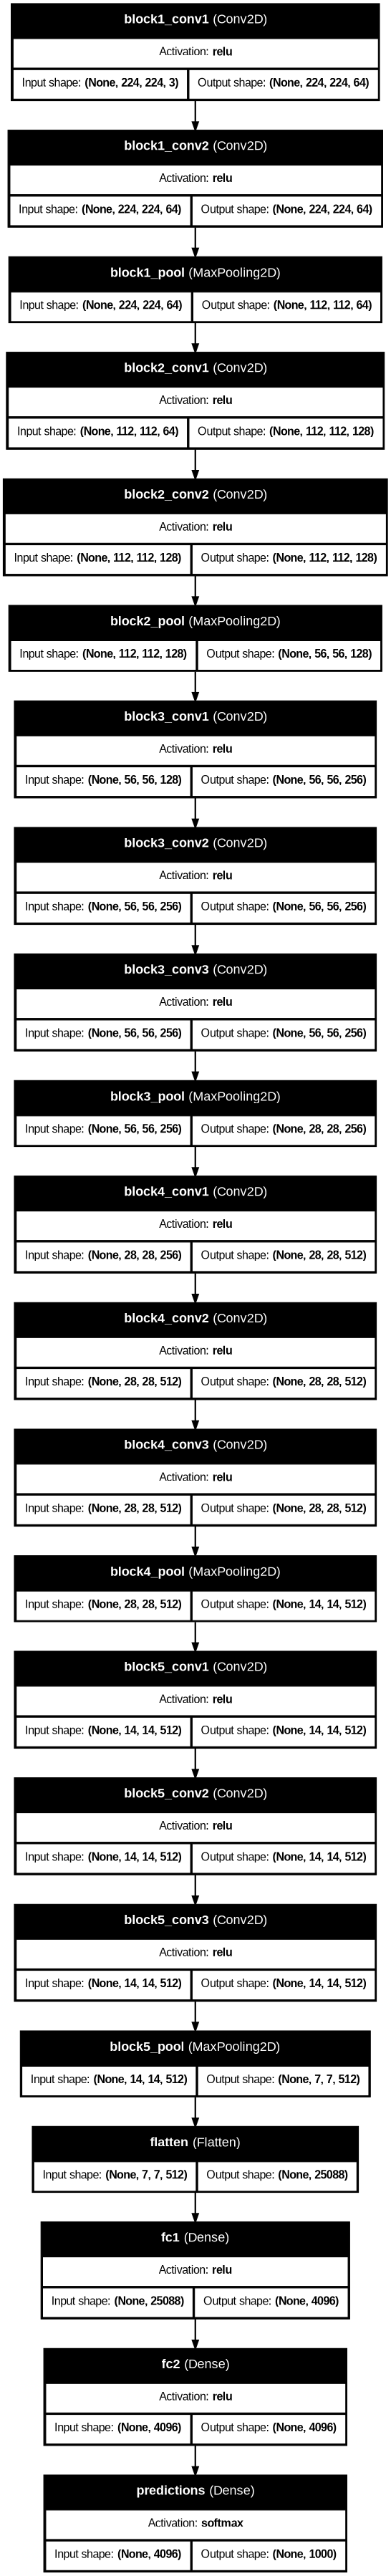

In [4]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

plot_model(
    vgg16,
    to_file="vgg16_keras_block_diagram.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    rankdir="TB",
    dpi=80
)
display(Image(filename="vgg16_keras_block_diagram.png", width=900))

## Why this notebook does not train VGG16

Training all 138 million parameters meaningfully requires a very large labeled dataset, extensive augmentation, and substantial GPU time. This lesson focuses on architecture construction and inference, so it loads proven ImageNet weights and performs no `compile()` or `fit()` operation.

## 6. Understand VGG16 preprocessing

Before prediction, an image must be:

- resized to 224 × 224,
- converted to a numeric array,
- placed inside a batch, and
- passed through VGG16's own `preprocess_input` function.

The official preprocessing converts RGB to BGR and zero-centers each color channel. It does **not** simply divide pixels by 255.

### Create a reusable prediction function

In [5]:
def classify_image(image_path, model=vgg16, top=5):
    # Keep one copy for display and resize another for VGG16
    display_image = keras.utils.load_img(image_path)
    model_image = keras.utils.load_img(image_path, target_size=(224, 224))

    # Convert the image into a batch with shape (1, 224, 224, 3)
    image_array = keras.utils.img_to_array(model_image)
    image_batch = np.expand_dims(image_array, axis=0)

    # Apply the exact preprocessing expected by VGG16
    processed_batch = keras.applications.vgg16.preprocess_input(
        image_batch.copy()
    )

    # Predict and translate the 1,000 scores into readable labels
    probabilities = model.predict(processed_batch, verbose=0)
    results = keras.applications.vgg16.decode_predictions(
        probabilities, top=top
    )[0]

    # Show the image
    plt.figure(figsize=(7, 5))
    plt.imshow(display_image)
    plt.title(f"Top prediction: {results[0][1].replace('_', ' ')}")
    plt.axis("off")
    plt.show()

    # Print the top predictions
    print("Top predictions:")
    for rank, (_, label, confidence) in enumerate(results, start=1):
        print(f"{rank}. {label.replace('_', ' '):25s} {confidence:.2%}")

    # Display a probability bar chart
    labels = [item[1].replace('_', ' ') for item in results][::-1]
    scores = [item[2] for item in results][::-1]
    plt.figure(figsize=(8, 4))
    plt.barh(labels, scores, color="#6957d5")
    plt.xlabel("Probability")
    plt.title("VGG16 Top Predictions")
    plt.xlim(0, 1)
    plt.grid(axis="x", alpha=0.25)
    plt.show()

    return results

## 7. Recognize a sample image

This official TensorFlow sample image is downloaded only to make the first demonstration reproducible.

83281/83281 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


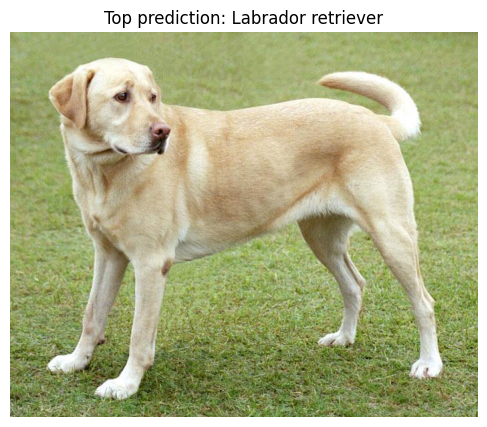

Top predictions:
1. Labrador retriever        35.92%
2. golden retriever          21.88%
3. Chesapeake Bay retriever  4.86%
4. kuvasz                    4.79%
5. redbone                   3.90%


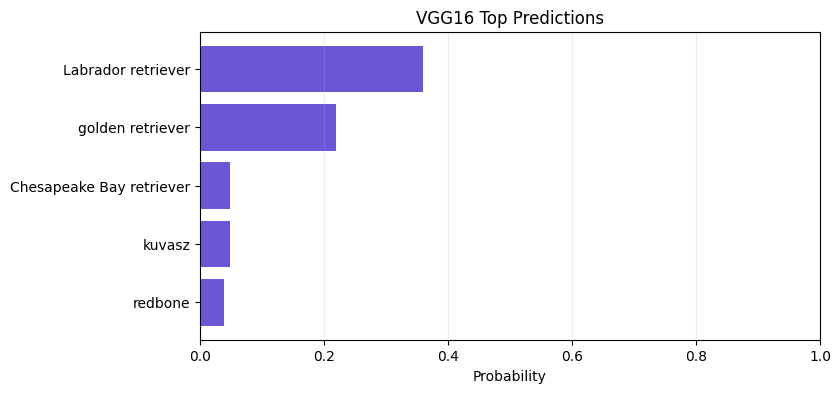

In [6]:
sample_url = (
    "https://storage.googleapis.com/download.tensorflow.org/"
    "example_images/YellowLabradorLooking_new.jpg"
)
sample_path = keras.utils.get_file(
    fname="yellow_labrador.jpg",
    origin=sample_url
)

sample_results = classify_image(sample_path)

## 8. Recognize your own image

Upload a `.jpg`, `.jpeg`, or `.png` image containing a clear everyday object. Remember that VGG16 can only return labels from the 1,000 ImageNet classes.

> This cell is specifically for Google Colab.

In [7]:
from google.colab import files

uploaded = files.upload()

if uploaded:
    uploaded_filename = next(iter(uploaded))
    uploaded_results = classify_image(uploaded_filename)

## 9. Optional: inspect intermediate feature maps

We can create a smaller model whose outputs come from selected VGG16 blocks. This helps students see how raw pixels gradually become abstract features.

## 10. Key ideas to review

- VGG16 has 13 convolution layers and 3 fully connected layers containing weights.
- Repeated 3 × 3 convolutions create a deep hierarchy of visual features.
- Max pooling reduces spatial size while channel depth increases.
- Pretrained ImageNet weights make useful image recognition possible without training from scratch.
- Correct preprocessing is part of the model pipeline, not an optional detail.

### Suggested classroom exercises

1. Upload images containing different everyday objects and compare the top five predictions.
2. Find an image that VGG16 misclassifies and discuss possible reasons.
3. Calculate how the spatial size changes after each max-pooling layer.
4. Compare the number of parameters in the convolution base with the dense classifier.
5. Compare VGG16's size and speed with MobileNet or EfficientNet.